In [1]:
import os
print(os.listdir())
print(os.path.isdir("data.csv"))
print(os.listdir("data.csv"))

['.ipynb_checkpoints', '01_sales_analysis.ipynb', 'data.csv']
True
['data.csv']


In [2]:
import pandas as pd

df = pd.read_csv("data.csv/data.csv", encoding="ISO-8859-1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


Part A: Cleaning and analysis
1.Handle missing values (CustomerID)

In [4]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
(df.isnull().sum() / len(df)) * 100


InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [6]:
df_clean = df.dropna(subset=["CustomerID"]).copy()
df_clean.shape

(406829, 8)

2. Remove duplicates

In [7]:
df_clean.duplicated().sum()

np.int64(5225)

In [8]:
df_clean = df_clean.drop_duplicates()

In [9]:
df_clean.shape

(401604, 8)

3. Remove cancelled orders and invalid rows (negative or zero quantity and price)

In [10]:
df_clean["InvoiceNo"].str.startswith("C").sum()
df_clean = df_clean[~df_clean["InvoiceNo"].str.startswith("C")]
df_clean.shape

(392732, 8)

In [11]:
(df_clean["Quantity"] <= 0).sum()

np.int64(0)

In [12]:
(df_clean["UnitPrice"] <= 0).sum()

np.int64(40)

In [13]:
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["UnitPrice"] > 0)]
df_clean.shape

(392692, 8)

4. Convert InvoiceDate to a real date and create a Revenue column

In [14]:
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"], format="%m/%d/%Y %H:%M")
df_clean["InvoiceDate"].head()

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[us]

In [15]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]
df_clean["Revenue"].sum()

np.float64(8887208.894000001)

5. Groupby: top products, top countries, revenue by month

In [16]:
df_clean.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64

In [17]:
df_clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

In [18]:
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M")
df_clean.groupby("YearMonth")["Revenue"].sum()

YearMonth
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: Revenue, dtype: float64

In [19]:
monthly = df_clean.groupby("YearMonth")["Revenue"].sum()
monthly.idxmax()

Period('2011-11', 'M')

In [20]:
df_clean.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64

Part B: Visualization and customers
6.Matplotlib and Seaborn charts

Matplotlib is building the font cache; this may take a moment.


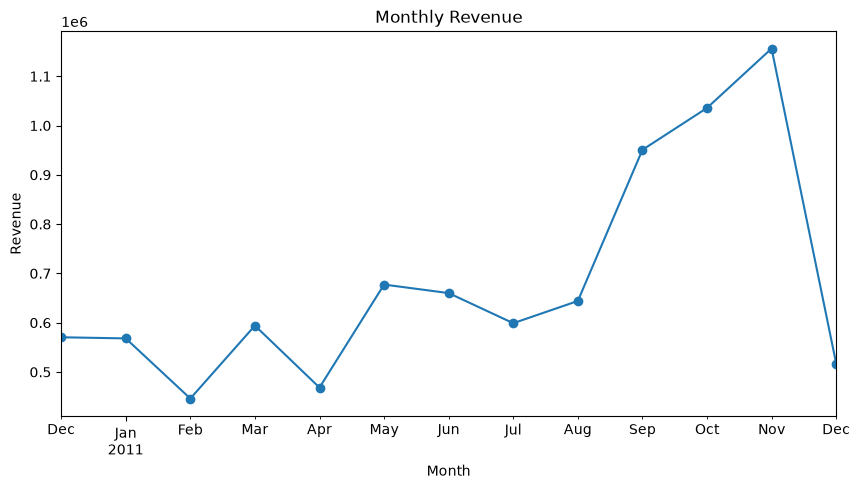

In [21]:
import matplotlib.pyplot as plt

monthly = df_clean.groupby("YearMonth")["Revenue"].sum()
monthly.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

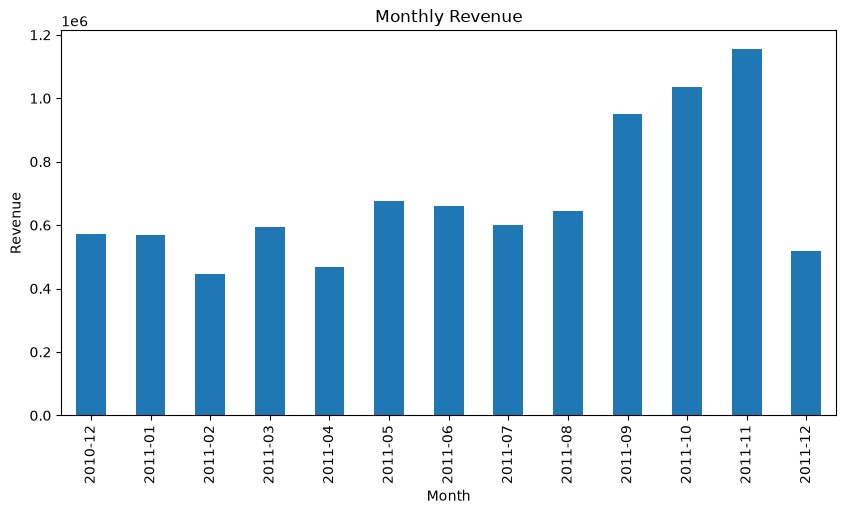

In [23]:
import matplotlib.pyplot as plt

monthly = df_clean.groupby("YearMonth")["Revenue"].sum()
monthly.plot(kind="bar", figsize=(10, 5))
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

In [24]:
df_clean["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

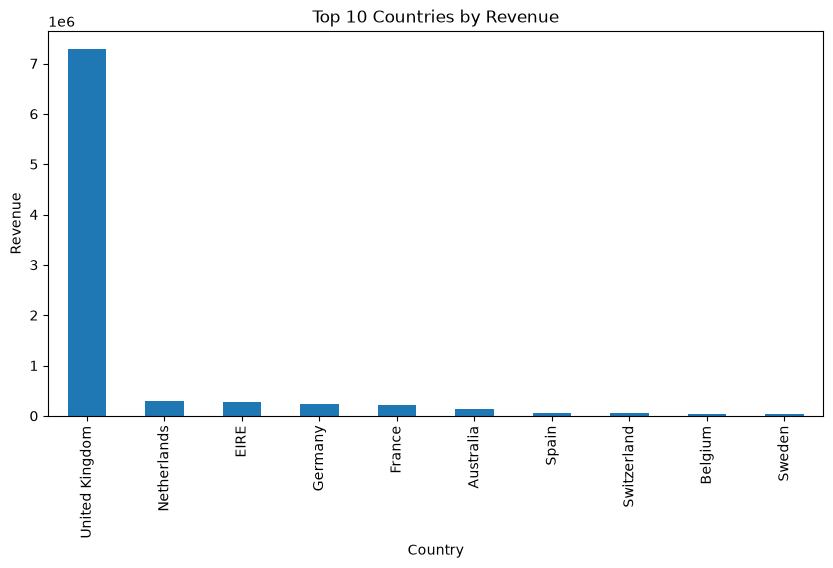

In [25]:
top_countries = df_clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)
top_countries.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Countries by Revenue")
plt.ylabel("Revenue")
plt.show()

In [26]:
country_revenue = df_clean.groupby("Country")["Revenue"].sum()
uk_share = country_revenue["United Kingdom"] / country_revenue.sum() * 100
print(round(uk_share, 1))

82.0


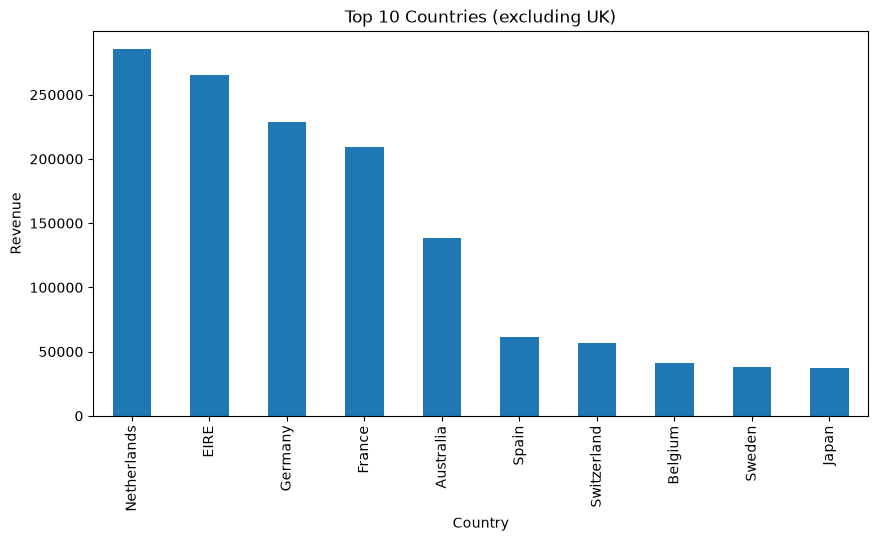

In [27]:
others = country_revenue.drop("United Kingdom").sort_values(ascending=False).head(10)
others.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Countries (excluding UK)")
plt.ylabel("Revenue")
plt.show()

In [28]:
df_clean.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(3)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
Name: Revenue, dtype: float64

In [29]:
df_clean[df_clean["Description"] == "PAPER CRAFT , LITTLE BIRDIE"][["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "Revenue"]]

,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Revenue
540421,581483,2011-12-09 09:15:00,80995,2.08,168469.6


In [30]:
df_clean = df_clean[df_clean["Quantity"] < 10000]
df_clean.shape

(392690, 10)

In [31]:
df_clean.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)

Description
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
CHILLI LIGHTS                          46265.11
PAPER CHAIN KIT 50'S CHRISTMAS         42584.13
Name: Revenue, dtype: float64

7. RFM customer scoring and segments
8. Quick statistics (mean vs median, outliers)

In [32]:
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)
last_purchase = df_clean.groupby("CustomerID")["InvoiceDate"].max()
recency = (snapshot_date - last_purchase).dt.days
recency.head()

CustomerID
12347.0      2
12348.0     75
12349.0     19
12350.0    310
12352.0     36
Name: InvoiceDate, dtype: int64

In [33]:
frequency = df_clean.groupby("CustomerID")["InvoiceNo"].nunique()
monetary = df_clean.groupby("CustomerID")["Revenue"].sum()

In [34]:
rfm = pd.DataFrame({"Recency": recency, "Frequency": frequency, "Monetary": monetary})
rfm.head()
rfm.shape

(4337, 3)

In [35]:
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04


In [36]:
rfm.describe()

,Recency,Frequency,Monetary
count,4337.000000,4337.000000,4337.000000
mean,92.529859,4.272539,1992.519182
std,99.968030,7.698808,8547.583474
min,1.000000,1.000000,2.900000
25%,18.000000,1.000000,306.450000
50%,51.000000,2.000000,668.430000
75%,142.000000,5.000000,1657.280000
max,374.000000,209.000000,280206.020000


In [37]:
rfm["R_score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1])
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
rfm["M_score"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5])
rfm.head()

,Recency,Frequency,Monetary,R_score,F_score,M_score
CustomerID,,,,,,
12347.0,2,7,4310.00,5,5,5
12348.0,75,4,1797.24,2,4,4
12349.0,19,1,1757.55,4,1,4
12350.0,310,1,334.40,1,1,2
12352.0,36,8,2506.04,3,5,5


In [38]:
rfm["R_score"] = rfm["R_score"].astype(int)
rfm["F_score"] = rfm["F_score"].astype(int)

def segment(row):
    if row["R_score"] >= 4 and row["F_score"] >= 4:
        return "Champions"
    elif row["R_score"] >= 3 and row["F_score"] >= 3:
        return "Loyal"
    elif row["R_score"] <= 2 and row["F_score"] >= 3:
        return "At Risk"
    elif row["R_score"] <= 2 and row["F_score"] <= 2:
        return "Lost"
    else:
        return "Potential"

rfm["Segment"] = rfm.apply(segment, axis=1)
rfm["Segment"].value_counts()

Segment
Champions    1139
Lost         1065
Loyal         820
Potential     670
At Risk       643
Name: count, dtype: int64

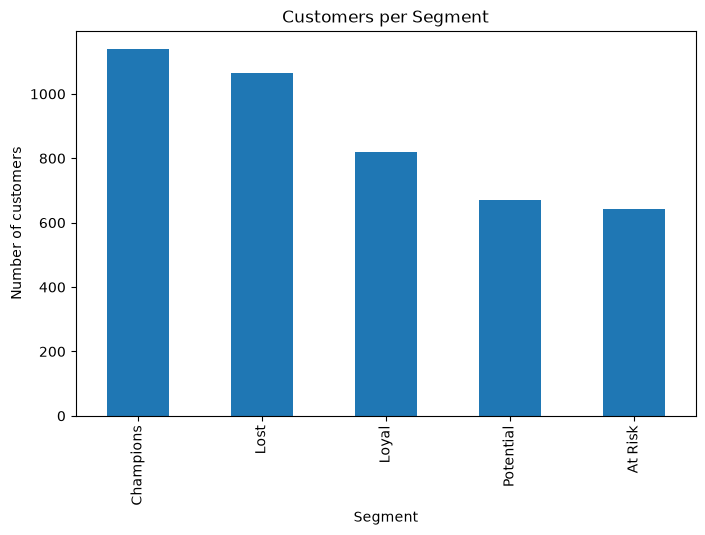

In [39]:
rfm["Segment"].value_counts().plot(kind="bar", figsize=(8, 5))
plt.title("Customers per Segment")
plt.ylabel("Number of customers")
plt.show()

In [40]:
rfm.groupby("Segment")[["Recency", "Frequency", "Monetary"]].mean().round(1)

,Recency,Frequency,Monetary
Segment,,,
At Risk,152.8,3.4,1241.1
Champions,13.3,10.0,5191.8
Lost,217.8,1.1,414.2
Loyal,38.1,3.6,1442.2
Potential,36.8,1.2,457.2


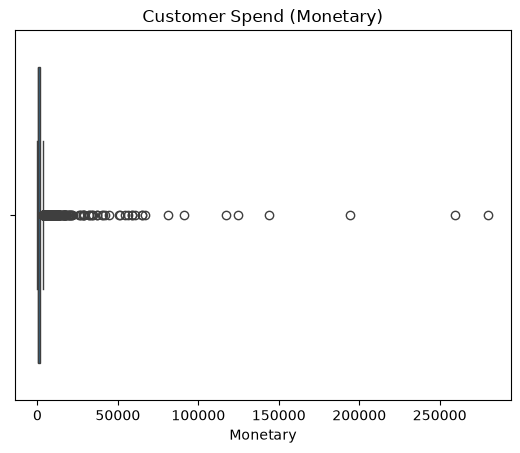

In [41]:
import seaborn as sns

sns.boxplot(x=rfm["Monetary"])
plt.title("Customer Spend (Monetary)")
plt.show()

In [43]:
rfm[["Recency", "Frequency", "Monetary"]].corr().round(2)

,Recency,Frequency,Monetary
Recency,1.00,-0.26,-0.13
Frequency,-0.26,1.00,0.58
Monetary,-0.13,0.58,1.00


Best month: November 2011 (holiday season)
UK brings 82% of revenue
Top product: REGENCY CAKESTAND 3 TIER
Found and removed a cancelled 80,995-unit order that inflated revenue by about 168K

Machine Learning Steps

In [2]:
import pandas as pd

df = pd.read_csv("data.csv/data.csv", encoding="ISO-8859-1")
df.shape

(541909, 8)

In [3]:
def add_revenue(data):
    data = data.copy()
    data["Revenue"] = data["Quantity"] * data["UnitPrice"]
    return data

test = add_revenue(df)
test[["Quantity", "UnitPrice", "Revenue"]].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


2) Turn your cleaning steps into functions

In [4]:
def drop_missing_customers(data):
    data = data.copy()
    data = data.dropna(subset=["CustomerID"])
    return data

step1 = drop_missing_customers(df)
step1.shape

(406829, 8)

In [8]:
def remove_cancelled(data):
    data = data.copy()
    data["InvoiceNo"].str.startswith("C").sum()
    data = data[~data["InvoiceNo"].str.startswith("C")]
    return data

step2 = remove_cancelled(step1)
step2.shape

(397924, 8)

In [13]:
clean = remove_cancelled(drop_missing_customers(df))
clean.shape

(397924, 8)

In [15]:
def remove_invalid(data):
    data = data.copy()
    data = data[(data["Quantity"] > 0) & (data["UnitPrice"] > 0)]
    return data

remove_invalid(clean).shape

(397884, 8)

##3) Standard column names

In [16]:
mapping = {
    "InvoiceDate": "Date",
    "CustomerID": "Customer",
    "InvoiceNo": "Invoice",
    "Quantity": "Quantity",
    "UnitPrice": "Price",
}
mapping["CustomerID"]

'Customer'

In [17]:
renamed = df.rename(columns=mapping)
renamed.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'Date', 'Price',
       'Customer', 'Country'],
      dtype='str')

In [18]:
def standardize_columns(data, mapping):
    data = data.copy()
    data = data.rename(columns=mapping)
    return data

In [19]:
std = standardize_columns(df, mapping)
std.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'Date', 'Price',
       'Customer', 'Country'],
      dtype='str')

In [20]:
std = standardize_columns(df, mapping)
drop_missing_customers(std)

KeyError: ['CustomerID']

In [21]:
def drop_missing_customers(data):
    data = data.copy()
    data = data.dropna(subset=["Customer"])
    return data

In [33]:
def remove_cancelled(data):
    data = data.copy()
    data = data[~data["Invoice"].str.startswith("C")]
    return data

In [30]:
def remove_invalid(data):
    data = data.copy()
    data = data[(data["Quantity"] > 0) & (data["Price"] > 0)]
    return data

In [31]:
def add_revenue(data):
    data = data.copy()
    data["Revenue"] = data["Quantity"] * data["Price"]
    return data

In [32]:
std = standardize_columns(df, mapping)
result = add_revenue(remove_invalid(remove_cancelled(drop_missing_customers(std))))
result.shape
result.head()

,Invoice,StockCode,Description,Quantity,Date,Price,Customer,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34


In [34]:
def convert_dates(data):
    data = data.copy()
    data["Date"] = pd.to_datetime(data["Date"], format="%m/%d/%Y %H:%M")
    return data

## One function that runs the whole pipeline
## Reusable cleaning pipeline

In [36]:
def clean_data(data, mapping):
    data = standardize_columns(data, mapping)
    data = drop_missing_customers(data)
    data = data[~data["Invoice"].str.startswith("C")]
    data = data[(data["Quantity"] > 0) & (data["Price"] > 0)]
    data["Date"] = pd.to_datetime(data["Date"], format="%m/%d/%Y %H:%M")
    data["Revenue"] = data["Quantity"] * data["Price"]
    return data

In [37]:
final = clean_data(df, mapping)
final.shape
final.dtypes

Invoice                   str
StockCode                 str
Description               str
Quantity                int64
Date           datetime64[us]
Price                 float64
Customer              float64
Country                   str
Revenue               float64
dtype: object

In [38]:
other = df.rename(columns={"InvoiceNo": "OrderID", "CustomerID": "ClientID",
                           "InvoiceDate": "OrderDate", "UnitPrice": "Price"})
other_mapping = {"OrderID": "Invoice", "ClientID": "Customer",
                 "OrderDate": "Date", "Quantity": "Quantity", "Price": "Price"}

clean_data(other, other_mapping).shape

(397884, 9)

In [39]:
len(df)
df.shape[1]
df.isnull().sum().sum()
df.duplicated().sum()

np.int64(5268)

In [42]:
def profile_data(data):
    report = {
        "rows": len(data),
        "columns": data.shape[1],
        "missing_cells": int(data.isnull().sum().sum()),
        "duplicate_rows": int(data.duplicated().sum()),
        "missing_by_column": data.isnull().sum().to_dict(),
        "negative_numbers": int((data["Quantity"] < 0).sum()),
    }
    return report

profile_data(df)

{'rows': 541909,
 'columns': 8,
 'missing_cells': 136534,
 'duplicate_rows': 5268,
 'missing_by_column': {'InvoiceNo': 0,
  'StockCode': 0,
  'Description': 1454,
  'Quantity': 0,
  'InvoiceDate': 0,
  'UnitPrice': 0,
  'CustomerID': 135080,
  'Country': 0},
 'negative_numbers': 10624}

In [43]:
REQUIRED = ["Invoice", "Customer", "Date", "Quantity", "Price"]

for col in REQUIRED:
    print(col)

"Price" in REQUIRED
"Colour" in REQUIRED

Invoice
Customer
Date
Quantity
Price


False

In [44]:
def check_columns(data):
    missing = []
    for col in REQUIRED:
        if col not in data.columns:
            missing.append(col)
    if len(missing) > 0:
        raise ValueError("Missing columns: " + ", ".join(missing))
    return data

In [45]:
std = standardize_columns(df, mapping)
check_columns(std).shape

(541909, 8)

In [46]:
check_columns(std.drop(columns=["Price"]))

ValueError: Missing columns: Price

In [47]:
clean_data(df, mapping).shape

(397884, 9)

In [48]:
def clean_data(data, mapping):
    data = standardize_columns(data, mapping)
    data = check_columns(data)
    data = drop_missing_customers(data)
    data = remove_cancelled(data)
    data = remove_invalid(data)
    data = convert_dates(data)
    data = add_revenue(data)
    return data

clean_data(df, mapping).shape

(397884, 9)

In [53]:
def remove_duplicates(data):
    data = data.copy()
    data = data.drop_duplicates()
    return data

In [50]:
df["Quantity"].quantile(0.99)
df["Quantity"].quantile(0.9999)

np.float64(1440.0)

In [51]:
def remove_outliers(data):
    data = data.copy()
    limit = data["Quantity"].quantile(0.9999)
    data = data[data["Quantity"] <= limit]
    return data

In [54]:
step = remove_duplicates(df)
step.shape

(536641, 8)

In [55]:
cleaned = clean_data(df, mapping)
cleaned.shape

no_outliers = remove_outliers(cleaned)
no_outliers.shape

(397844, 9)

In [56]:
def clean_data(data, mapping):
    data = standardize_columns(data, mapping)
    data = check_columns(data)
    data = remove_duplicates(data)
    data = drop_missing_customers(data)
    data = remove_cancelled(data)
    data = remove_invalid(data)
    data = remove_outliers(data)
    data = convert_dates(data)
    data = add_revenue(data)
    return data

final = clean_data(df, mapping)
final.shape

(392652, 9)

In [57]:
pd.to_datetime("12/25/2011", format="%m/%d/%Y")
pd.to_datetime("25-12-2011", format="%d-%m-%Y")

Timestamp('2011-12-25 00:00:00')

In [58]:
try:
    pd.to_datetime("25/12/2011", format="%m/%d/%Y")
    print("worked")
except ValueError:
    print("that format did not match")

that format did not match


In [59]:
DATE_FORMATS = ["%m/%d/%Y %H:%M", "%d/%m/%Y %H:%M", "%Y-%m-%d %H:%M:%S", "%Y-%m-%d"]

def convert_dates(data):
    data = data.copy()
    for fmt in DATE_FORMATS:
        try:
            data["Date"] = pd.to_datetime(data["Date"], format=fmt)
            return data
        except ValueError:
            continue
    raise ValueError("Could not understand the Date column format")

In [61]:
final = clean_data(df, mapping)
final.shape

(392652, 9)

In [62]:
def clean_data(data, mapping):
    data = standardize_columns(data, mapping)
    data = check_columns(data)
    data = remove_duplicates(data)
    data = drop_missing_customers(data)
    data = remove_cancelled(data)
    data = remove_invalid(data)
    data = remove_outliers(data)
    data = convert_dates(data)
    data = add_revenue(data)
    return data

final = clean_data(df, mapping)
final.shape

(392652, 9)